# 2. Gene selection under nested cross-validation, and a leakage check

The candidate pool of notebook 1 holds far more genes than the development set has deaths, so a survival model needs a short gene list. This notebook compares several ways of choosing that list under one protocol, measures how much a selection made outside the cross-validation inflates the score, and states which method a rule fixed in advance picks. Only the development set is used.

## Settings

The first cell loads the libraries and locates the files. The second names every fold count, seed, threshold and grid, with its reason beside it.

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # folds run in parallel processes; one thread each avoids oversubscribing the cores

import hashlib, json, subprocess, sys, time
from importlib.metadata import version
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from scipy import optimize, stats
from sklearn.model_selection import StratifiedKFold
from sksurv.linear_model import CoxnetSurvivalAnalysis, CoxPHSurvivalAnalysis
from sksurv.metrics import concordance_index_censored, concordance_index_ipcw
from sksurv.util import Surv

REPO = Path(subprocess.run(["git", "rev-parse", "--show-toplevel"], capture_output=True, text=True, check=True).stdout.strip())
DEVELOPMENT_FILE = REPO / "data" / "processed" / "tcga_development.parquet"  # written by notebook 1; ignored by git
DATA_RESULTS = REPO / "results" / "01_data"
RESULTS = REPO / "results" / "02_gene_selection"  # per-fold results and tables of this notebook; tracked by git
RESULTS.mkdir(parents=True, exist_ok=True)

In [2]:
OUTER_FOLDS, OUTER_SEEDS = 5, [1, 2, 3, 4, 5]  # 5-fold cross-validation repeated 5 times: 25 held-out folds
INNER_FOLDS, INNER_SEED = 5, 0                 # tuning folds inside each training part
EXPRESSED_LOG2, EXPRESSED_SHARE = 1.0, 0.2     # keep a gene with TPM >= 1, that is log2(TPM + 1) >= 1, in at least 20% of training patients
LIST_SIZES = [50, 100, 200, 500]               # list sizes offered to the two ranking methods
L1_SHARES = [0.25, 0.5, 0.75]                  # elastic-net mixes between pure ridge (0) and pure LASSO (1)
PATH_LENGTH, PATH_DEPTH = 50, 0.01             # 50 penalties from the largest down to 1% of it, the library default
MAX_GENES = 500                                # longest list a penalty path may offer, equal to the largest list size above
RIDGE_GRID = [100.0, 1000.0, 10000.0]          # ridge penalty of the scoring model: weak, medium and strong shrinkage
CLINICAL_RIDGE = 0.001                         # numerical safeguard on the clinical coefficients, negligible against the data
OPTIMISER = {"gtol": 1e-8, "ftol": 1e-15, "maxiter": 100000, "maxfun": 1000000}  # let the Cox fit run until its gradient is practically zero
GRADIENT_LIMIT = 1e-3                          # largest gradient entry accepted at the end of a Cox fit; the likelihood itself is in the hundreds
DAYS_PER_YEAR = 365.25                         # average length of a year, leap years included
UNO_HORIZON = 5 * DAYS_PER_YEAR                # Uno's C is truncated at 5 years
LEAKAGE_LIST_SIZE = 100                        # list size in the leakage check and in the shuffled-outcome check
SHUFFLE_SEEDS = [1, 2, 3, 4, 5]                # shuffled-outcome check: five shuffles of the outcomes
STABLE_SHARE = 0.8                             # a gene counts as stable when at least 80% of the lists contain it
CONFIDENCE = 0.95                              # level of every interval
TOP_GENES = 20                                 # most often selected genes shown per method
CHECK_SEED = 0                                 # seed of the small synthetic examples used in the checks
N_JOBS = 4                                     # outer folds evaluated in parallel, one per physical core of the machine used
# Indicator columns of the clinical model; the most common level of each variable is the reference and gets no column.
CLINICAL_LEVELS = {"stage": ["I", "III", "IV", "unknown"], "er": ["negative", "unknown"],
                   "pr": ["negative", "unknown"], "her2": ["positive", "unknown"]}
INSIDE, ON_ALL = "selection inside the training fold", "selection on all patients"  # the two ways of selecting that are contrasted

## What is compared

The table names everything that is compared and says whether it looks at patient outcomes when it picks genes. A method that uses outcomes can fit noise, which is why the selection has to be repeated inside every training part. The last row was planned and not run.

In [3]:
METHODS = {
    "clinical only": {"kind": "no genes", "uses outcomes": "picks no genes",
                      "does": "no gene: a Cox model on age, stage, ER, PR and HER2, the reference"},
    "most variable genes": {"kind": "ranking by variance", "sizes": LIST_SIZES, "uses outcomes": "no",
                            "does": "ranks genes by the variance of their expression and keeps the top of the ranking"},
    "one-gene Cox ranking": {"kind": "ranking by score test", "sizes": LIST_SIZES, "uses outcomes": "yes",
                             "does": "ranks genes by a test of each gene alone in a Cox model and keeps the top of the ranking"},
    "LASSO-Cox": {"kind": "penalised Cox", "l1_shares": [1.0], "uses outcomes": "yes",
                  "does": "fits one Cox model on all genes with a penalty that sets most coefficients to zero; the remaining genes are the list"},
    "elastic-net Cox": {"kind": "penalised Cox", "l1_shares": L1_SHARES, "uses outcomes": "yes",
                        "does": "as LASSO-Cox, with a mixed penalty that lets correlated genes enter together"}}
NOT_RUN = {"the earlier pipeline's selector": {"uses outcomes": "yes, as classes",
           "does": "LASSO on survival classes; planned, and not run because its built-in cross-validation exceeded the compute limit"}}


def show_table(rows, first_column):
    """Render a dictionary of rows as a Markdown table, which wraps long sentences."""
    columns = list(next(iter(rows.values())))
    lines = [f"| {first_column} | " + " | ".join(columns) + " |", "|---" * (len(columns) + 1) + "|"]
    lines += [f"| {name} | " + " | ".join(str(row[column]) for column in columns) + " |" for name, row in rows.items()]
    display(Markdown("\n".join(lines)))


show_table({name: {"what it does": row["does"], "uses patient outcomes to pick genes": row["uses outcomes"]}
            for name, row in {**METHODS, **NOT_RUN}.items()}, "name")

| name | what it does | uses patient outcomes to pick genes |
|---|---|---|
| clinical only | no gene: a Cox model on age, stage, ER, PR and HER2, the reference | picks no genes |
| most variable genes | ranks genes by the variance of their expression and keeps the top of the ranking | no |
| one-gene Cox ranking | ranks genes by a test of each gene alone in a Cox model and keeps the top of the ranking | yes |
| LASSO-Cox | fits one Cox model on all genes with a penalty that sets most coefficients to zero; the remaining genes are the list | yes |
| elastic-net Cox | as LASSO-Cox, with a mixed penalty that lets correlated genes enter together | yes |
| the earlier pipeline's selector | LASSO on survival classes; planned, and not run because its built-in cross-validation exceeded the compute limit | yes, as classes |

## Fixed before running

The protocol below was written down and committed before any model saw a real outcome. The table is rendered from the settings above, so it cannot drift from the code. Harrell's C, the main metric, is the share of comparable patient pairs that a model ranks in the right order: 0.5 is chance and 1 is a perfect ranking. Uno's C is a variant that corrects for censoring. A gene list is scored by a Cox model refit on it, the scoring model, which is defined further down.

In [4]:
show_table({
    "Data": {"fixed choice": "the development set of notebook 1 only"},
    "Outcome": {"fixed choice": "overall survival as time and event"},
    "Primary metric": {"fixed choice": "Harrell's C on the outer validation folds"},
    "Secondary metric": {"fixed choice": f"Uno's C truncated at {UNO_HORIZON / DAYS_PER_YEAR:.0f} years"},
    "Resampling": {"fixed choice": f"{OUTER_FOLDS} outer folds repeated {len(OUTER_SEEDS)} times (seeds {OUTER_SEEDS[0]} to {OUTER_SEEDS[-1]}), "
                                   f"stratified by event; all tuning in {INNER_FOLDS} inner folds of each outer training part"},
    "Fitted on training parts only": {"fixed choice": "expression filter, z-scoring, age median, selection, tuning, the scoring model"},
    "Scoring model": {"fixed choice": "ridge Cox refit on the listed genes, in two forms: genes only (primary) and genes plus clinical (secondary)"},
    "Tuning": {"fixed choice": f"list size in {LIST_SIZES} for the two ranking methods; a path of {PATH_LENGTH} penalties for LASSO-Cox and "
                               f"elastic-net Cox (L1 share in {L1_SHARES}), lists of at most {MAX_GENES} genes; ridge penalty of the scoring "
                               f"model in {RIDGE_GRID}; the highest mean inner-fold Harrell's C wins"},
    "Primary comparison": {"fixed choice": f"elastic-net Cox lists score higher than LASSO-Cox lists, genes only; a null if the {CONFIDENCE:.0%} "
                                           "interval of the mean paired difference includes 0"},
    "Interval": {"fixed choice": "corrected resampled t for repeated cross-validation"},
    "Choice rule": {"fixed choice": "highest mean C, genes only; methods whose interval against it includes 0 are tied; among tied methods "
                                    "prefer one that uses no outcome, then the higher Jaccard index"},
    "Leakage check": {"fixed choice": f"{ON_ALL} against {INSIDE}, for one-gene Cox ranking at {LEAKAGE_LIST_SIZE} genes, LASSO-Cox and elastic-net Cox"},
    "Shuffled-outcome check": {"fixed choice": f"the same contrast for one-gene Cox ranking on {len(SHUFFLE_SEEDS)} shuffles of the outcomes, run first; "
                                               f"with {INSIDE} the interval must include 0.50"},
    "Compute rule": {"fixed choice": "8 hours in total; if the projection is over, reduce the repeats from 5 to 3, then drop the earlier pipeline's selector"}},
    "item")

| item | fixed choice |
|---|---|
| Data | the development set of notebook 1 only |
| Outcome | overall survival as time and event |
| Primary metric | Harrell's C on the outer validation folds |
| Secondary metric | Uno's C truncated at 5 years |
| Resampling | 5 outer folds repeated 5 times (seeds 1 to 5), stratified by event; all tuning in 5 inner folds of each outer training part |
| Fitted on training parts only | expression filter, z-scoring, age median, selection, tuning, the scoring model |
| Scoring model | ridge Cox refit on the listed genes, in two forms: genes only (primary) and genes plus clinical (secondary) |
| Tuning | list size in [50, 100, 200, 500] for the two ranking methods; a path of 50 penalties for LASSO-Cox and elastic-net Cox (L1 share in [0.25, 0.5, 0.75]), lists of at most 500 genes; ridge penalty of the scoring model in [100.0, 1000.0, 10000.0]; the highest mean inner-fold Harrell's C wins |
| Primary comparison | elastic-net Cox lists score higher than LASSO-Cox lists, genes only; a null if the 95% interval of the mean paired difference includes 0 |
| Interval | corrected resampled t for repeated cross-validation |
| Choice rule | highest mean C, genes only; methods whose interval against it includes 0 are tied; among tied methods prefer one that uses no outcome, then the higher Jaccard index |
| Leakage check | selection on all patients against selection inside the training fold, for one-gene Cox ranking at 100 genes, LASSO-Cox and elastic-net Cox |
| Shuffled-outcome check | the same contrast for one-gene Cox ranking on 5 shuffles of the outcomes, run first; with selection inside the training fold the interval must include 0.50 |
| Compute rule | 8 hours in total; if the projection is over, reduce the repeats from 5 to 3, then drop the earlier pipeline's selector |

## The development set

We load the development file and compare its checksum with the one notebook 1 recorded, so the experiment provably runs on the locked split. The data are turned into plain arrays: the expression matrix, the outcome, the age, and indicator columns for the clinical levels.

In [5]:
recorded = json.loads((DATA_RESULTS / "split.json").read_text())["tcga_development"]
file_sha256 = hashlib.sha256(DEVELOPMENT_FILE.read_bytes()).hexdigest()
development = pd.read_parquet(DEVELOPMENT_FILE)
gene_ids = [column for column in development.columns if column.startswith("ENSG")]
symbols = pd.read_csv(DATA_RESULTS / "gene_pool.csv").set_index("gene_id")["symbol"]
data = {"expression": development[gene_ids].to_numpy(),
        "time": development["os_days"].to_numpy(dtype=float),
        "event": development["os_event"].to_numpy(dtype=bool),
        "age": development["age"].to_numpy(dtype=float),
        "indicators": np.column_stack([development[name] == level for name, levels in CLINICAL_LEVELS.items()
                                       for level in levels]).astype(float)}
display(Markdown(f"Development set: {len(development)} patients, {data['event'].sum()} deaths, {len(gene_ids)} candidate genes, "
                 f"{data['indicators'].shape[1] + 1} clinical columns."))

Development set: 864 patients, 121 deaths, 19211 candidate genes, 11 clinical columns.

In [6]:
# The experiment is only valid on the split that notebook 1 locked.
assert file_sha256 == recorded["file sha256"], "the development file differs from the one notebook 1 wrote"
assert len(development) == recorded["patients"] and data["event"].sum() == recorded["deaths"], "the cohort counts differ"

## Preparing a fold

Every step that learns from data is fitted on the training part of a fold and then applied to the held-out part: the expression filter, the scaling of each gene to mean 0 and variance 1 (z-scoring), and the median used for a missing age. Using held-out patients in any of these steps is called leakage: the evaluation would then test a model on patients that helped to build it.

In [7]:
def prepare_fold(data, train, valid):
    """Fit the filter, the scaling and the age fill on the training patients and apply them to both parts."""
    log_train = data["expression"][train]
    mean, sd = log_train.mean(axis=0), log_train.std(axis=0)
    sd[sd == 0] = 1.0  # a constant gene never passes the filter; this only avoids a division by zero
    age = np.where(np.isnan(data["age"]), np.nanmedian(data["age"][train]), data["age"])
    clinical = np.column_stack([(age - age[train].mean()) / age[train].std(), data["indicators"]])
    return {"genes_train": (log_train - mean) / sd, "genes_valid": (data["expression"][valid] - mean) / sd,
            "expressed": np.flatnonzero((log_train >= EXPRESSED_LOG2).mean(axis=0) >= EXPRESSED_SHARE),
            "variance": log_train.var(axis=0),
            "clinical_train": clinical[train], "clinical_valid": clinical[valid],
            "y_train": Surv.from_arrays(data["event"][train], data["time"][train]),
            "y_valid": Surv.from_arrays(data["event"][valid], data["time"][valid])}

In [8]:
# Leakage check: nothing fitted in prepare_fold may depend on the held-out patients, so replacing them by noise must change nothing.
rng = np.random.default_rng(CHECK_SEED)
half = len(data["time"]) // 2
train, valid = np.arange(half), np.arange(half, len(data["time"]))
noisy = {**data, "expression": data["expression"].copy(), "age": data["age"].copy()}
noisy["expression"][valid] = rng.normal(size=(len(valid), len(gene_ids)))
noisy["age"][valid] = rng.normal(size=len(valid))
original, scrambled = prepare_fold(data, train, valid), prepare_fold(noisy, train, valid)
assert all(np.array_equal(original[key], scrambled[key]) for key in ["genes_train", "expressed", "variance", "clinical_train"]), \
    "a step of prepare_fold uses the held-out patients"

## The scoring model

A gene list is scored by a Cox regression refit on it, the scoring model. Cox regression is the standard model for censored survival times: every patient gets a risk score, a weighted sum of the covariates, and a higher score means a higher hazard, the momentary risk of death. The refit uses a ridge penalty, which shrinks all coefficients towards zero, and is scored on patients it has not seen. It has two forms: genes only, and genes plus clinical, where the clinical covariates join the genes, practically unpenalised. An empty list scores 0.5.

In [9]:
def scoring_model_risk(fold, genes, ridge, with_clinical=False):
    """Refit the ridge Cox model on the listed genes and return its risk score for the held-out patients."""
    train, valid = fold["genes_train"][:, genes], fold["genes_valid"][:, genes]
    penalty = np.full(len(genes), ridge)
    if with_clinical:
        train, valid = np.hstack([fold["clinical_train"], train]), np.hstack([fold["clinical_valid"], valid])
        penalty = np.concatenate([np.full(fold["clinical_train"].shape[1], CLINICAL_RIDGE), penalty])
    if train.shape[1] == 0:
        return np.zeros(len(valid))  # no column at all: every patient gets the same score, which Harrell's C counts as 0.5
    return valid @ fit_ridge_cox(train, fold["y_train"]["time"], fold["y_train"]["event"], penalty)


def harrell_c(fold, risk):
    return concordance_index_censored(fold["y_valid"]["event"], fold["y_valid"]["time"], risk)[0]


def uno_c(fold, risk):
    return concordance_index_ipcw(fold["y_train"], fold["y_valid"], risk, tau=UNO_HORIZON)[0]

The library has the Cox model with a ridge penalty, but its solver needs seconds per fit with hundreds of genes, and the experiment fits the scoring model many thousands of times. We therefore write down the penalised likelihood of the model and its gradient and let SciPy's optimiser find the coefficients. The assert cell checks on a synthetic example that this fit and the library's give the same coefficients.

In [10]:
def fit_ridge_cox(X, time, event, penalty):
    """Coefficients of a Cox model with one ridge penalty per column (patients with tied times share a risk set)."""
    order = np.argsort(-time, kind="stable")  # longest time first: a running sum is then a sum over the patients still at risk
    X, time, deaths = X[order], time[order], np.flatnonzero(event[order])
    last_at_risk = np.searchsorted(-time, -time, side="right")[deaths] - 1  # last row of the risk set of each death
    death_sum = X[deaths].sum(axis=0)

    def negative_log_likelihood(beta):
        weight = np.exp(X @ beta)
        total = np.cumsum(weight)[last_at_risk]
        weighted = np.cumsum(weight[:, None] * X, axis=0)[last_at_risk]
        value = np.log(total).sum() - death_sum @ beta + 0.5 * penalty @ beta ** 2
        gradient = (weighted / total[:, None]).sum(axis=0) - death_sum + penalty * beta
        return value, gradient

    fit = optimize.minimize(negative_log_likelihood, np.zeros(X.shape[1]), jac=True, method="L-BFGS-B", options=OPTIMISER)
    assert np.abs(negative_log_likelihood(fit.x)[1]).max() < GRADIENT_LIMIT, "the Cox fit stopped before reaching its optimum"
    return fit.x

In [11]:
# The fit of the scoring model must agree with the Cox model of the library.
# Synthetic example: 200 patients, 12 columns, whole-number times so that ties occur, two penalty levels as in the genes plus clinical form.
rng = np.random.default_rng(CHECK_SEED)
x, t, e = rng.normal(size=(200, 12)), rng.integers(1, 40, size=200).astype(float), rng.random(200) < 0.5
penalty = np.concatenate([np.full(4, CLINICAL_RIDGE), np.full(8, RIDGE_GRID[0])])
library = CoxPHSurvivalAnalysis(alpha=penalty).fit(x, Surv.from_arrays(e, t)).coef_
assert np.allclose(fit_ridge_cox(x, t, e, penalty), library, atol=1e-5), "the fit disagrees with the library's Cox model"

## The selection methods

The ranking by variance needs no code of its own. The one-gene Cox ranking uses a score test: for each gene alone, it asks how strongly expression and hazard go together in a one-gene Cox model. The library has no fast version of this test, so the next cell computes it for all genes at once; the cell after it checks the result against the textbook formula on a small synthetic example.

In [12]:
def cox_score_statistics(Z, time, event):
    """Score test statistic of every column of Z in its own one-gene Cox model (tied times share one risk set)."""
    order = np.argsort(-time, kind="stable")  # longest time first: a running sum is then a sum over the patients still at risk
    Z, time, event = Z[order], time[order], event[order]
    at_risk = np.searchsorted(-time, -time, side="right")[event]  # size of the risk set at each death
    mean = np.cumsum(Z, axis=0)[at_risk - 1] / at_risk[:, None]
    mean_of_squares = np.cumsum(Z ** 2, axis=0)[at_risk - 1] / at_risk[:, None]
    observed_minus_expected = (Z[event] - mean).sum(axis=0)
    return observed_minus_expected / np.sqrt((mean_of_squares - mean ** 2).sum(axis=0))

In [13]:
# The fast score test must agree with the textbook formula computed death by death.
# Synthetic example: 40 patients, 3 genes, whole-number times up to 14 so that ties occur, about half of the patients die.
rng = np.random.default_rng(CHECK_SEED)
z, t, e = rng.normal(size=(40, 3)), rng.integers(1, 15, size=40).astype(float), rng.random(40) < 0.5
slow = np.zeros(3)
spread = np.zeros(3)
for death in np.flatnonzero(e):
    risk_set = z[t >= t[death]]
    slow += z[death] - risk_set.mean(axis=0)
    spread += risk_set.var(axis=0)
assert np.allclose(cox_score_statistics(z, t, e), slow / np.sqrt(spread)), "the fast score test disagrees with the formula"

LASSO-Cox is a Cox model on all genes with a penalty that sets most coefficients exactly to zero; the genes left with a non-zero coefficient are the list. The elastic net mixes that penalty with a ridge penalty and lets correlated genes enter together. Both are fitted along a path of penalties, and each penalty yields one candidate list. The function below returns every list a method offers on one training part.

In [14]:
def candidate_lists(method, fold, settings=None):
    """All gene lists a method offers on one training part, keyed by setting. Inner folds reuse the settings of the outer fit."""
    expressed, y = fold["expressed"], fold["y_train"]
    Z = fold["genes_train"][:, expressed]
    if method["kind"] == "fixed list":
        return {"fixed": np.asarray(method["genes"], dtype=int)}
    if method["kind"].startswith("ranking"):
        by_variance = method["kind"] == "ranking by variance"
        score = fold["variance"][expressed] if by_variance else np.abs(cox_score_statistics(Z, y["time"], y["event"]))
        ranking = expressed[np.argsort(-score, kind="stable")]
        return {size: ranking[:size] for size in method["sizes"]}
    lists = {}
    for share in method["l1_shares"]:
        penalties = None if settings is None else [penalty for s, penalty in settings if s == share]
        path = CoxnetSurvivalAnalysis(l1_ratio=share, n_alphas=PATH_LENGTH, alpha_min_ratio=PATH_DEPTH, alphas=penalties).fit(Z, y)
        for column, penalty in enumerate(path.alphas_):
            genes = expressed[np.flatnonzero(path.coef_[:, column])]
            if settings is not None or len(genes) <= MAX_GENES:  # the length limit is applied once, on the outer training part
                lists[(share, float(penalty))] = genes
    return lists

## Nested cross-validation

Cross-validation holds out one fold of patients, fits on the rest and scores on the held-out fold. In nested cross-validation every choice is itself made by an inner cross-validation that only sees the training part: here the setting of the method and the ridge penalty of the scoring model. The selection is redone on every inner training part. The held-out fold is used once, to score the list that was chosen without it.

In [15]:
def tune_and_select(method, data, train, outer):
    """Choose the setting of a method and the ridge penalty of the scoring model on inner folds of the training patients."""
    lists = candidate_lists(method, outer)
    scores = {(setting, ridge): [] for setting in lists for ridge in RIDGE_GRID}
    inner_folds = StratifiedKFold(INNER_FOLDS, shuffle=True, random_state=INNER_SEED).split(train, data["event"][train])
    for inner_train, inner_valid in inner_folds:
        inner = prepare_fold(data, train[inner_train], train[inner_valid])
        inner_lists = candidate_lists(method, inner, settings=list(lists))
        for setting, ridge in scores:
            scores[(setting, ridge)].append(harrell_c(inner, scoring_model_risk(inner, inner_lists[setting], ridge)))
    setting, ridge = max(scores, key=lambda key: np.mean(scores[key]))  # a tie goes to the first entry in grid order
    return lists[setting], ridge, setting


def evaluate_fold(method, data, train, valid):
    """One outer fold: tune on the training patients only, then score the chosen list once on the held-out patients."""
    outer = prepare_fold(data, train, valid)
    if method["kind"] == "no genes":
        genes, ridge, setting = np.array([], dtype=int), 0.0, "none"
    else:
        genes, ridge, setting = tune_and_select(method, data, train, outer)
    risk, risk_with_clinical = scoring_model_risk(outer, genes, ridge), scoring_model_risk(outer, genes, ridge, with_clinical=True)
    return {"harrell_genes_only": harrell_c(outer, risk), "uno_genes_only": uno_c(outer, risk),
            "harrell_genes_plus_clinical": harrell_c(outer, risk_with_clinical),
            "uno_genes_plus_clinical": uno_c(outer, risk_with_clinical),
            "genes": [int(gene) for gene in genes], "setting": str(setting), "ridge": ridge}

The outer folds of a run are evaluated in parallel. Every finished run is saved under `results/02_gene_selection/` with the commit that produced it and its running time; a later execution of the notebook reads the saved file, and deleting a file makes the notebook compute it again.

In [16]:
def run_method(method, data, seeds):
    """Evaluate a method on every outer fold of every repeat."""
    folds = [(seed, index, train, valid) for seed in seeds for index, (train, valid) in
             enumerate(StratifiedKFold(OUTER_FOLDS, shuffle=True, random_state=seed).split(data["event"], data["event"]))]
    records = Parallel(n_jobs=N_JOBS)(delayed(evaluate_fold)(method, data, train, valid) for _, _, train, valid in folds)
    return [{"repeat": seed, "fold": index, **record, "genes": [gene_ids[gene] for gene in record["genes"]]}  # lists saved by Ensembl ID
            for (seed, index, _, _), record in zip(folds, records)]


def saved(*name_parts, compute):
    """Return the saved result of a run, or compute it, save it and return it. The file is named after what the run is."""
    path = RESULTS / ("_".join(name_parts).lower().replace("-", "_").replace(" ", "_") + ".json")
    if not path.exists():
        started = time.time()
        result = compute()
        commit = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True, check=True).stdout.strip()
        path.write_text(json.dumps({"git commit": commit, "seconds": round(time.time() - started), "result": result}, indent=1))
    return json.loads(path.read_text())["result"]


def selected_on_all(method, data):
    """Run the whole selection, tuning included, once on all patients. Returns the list as Ensembl IDs."""
    everyone = np.arange(len(data["time"]))
    return [gene_ids[gene] for gene in tune_and_select(method, data, everyone, prepare_fold(data, everyone, everyone))[0]]


def fixed_list(genes):
    """A method that always offers the given list of Ensembl IDs, so that only the scoring model is tuned and scored."""
    return {"kind": "fixed list", "genes": pd.Index(gene_ids).get_indexer(genes)}

## Shuffled-outcome check

Before any real outcome is modelled we test the machinery itself. We shuffle the outcomes across patients, which destroys every true link between genes and survival, and run the one-gene Cox ranking both ways: with selection inside the training fold, and with selection on all patients before the cross-validation. A correct pipeline must score about 0.5 with selection inside the training fold. The other row shows how much score can appear from selection alone.

In [17]:
def shuffled_outcome_check():
    rows = []
    method = {"kind": "ranking by score test", "sizes": [LEAKAGE_LIST_SIZE]}
    for seed in SHUFFLE_SEEDS:
        order = np.random.default_rng(seed).permutation(len(data["time"]))
        shuffled = {**data, "time": data["time"][order], "event": data["event"][order]}
        for arm, arm_method in [(INSIDE, method), (ON_ALL, fixed_list(selected_on_all(method, shuffled)))]:
            rows += [{"shuffle": seed, "arm": arm, **record} for record in run_method(arm_method, shuffled, [seed])]
    return rows


def t_interval(values):
    """Mean and t interval of a few independent values."""
    values = np.asarray(values, dtype=float)
    half = stats.t.ppf((1 + CONFIDENCE) / 2, len(values) - 1) * values.std(ddof=1) / np.sqrt(len(values))
    return values.mean(), values.mean() - half, values.mean() + half


shuffled_runs = pd.DataFrame(saved("shuffled-outcome check", compute=shuffled_outcome_check))
shuffle_means = shuffled_runs.groupby(["arm", "shuffle"])["harrell_genes_only"].mean().unstack("arm")
shuffled_table = pd.DataFrame({arm: t_interval(shuffle_means[arm]) for arm in [INSIDE, ON_ALL]},
                              index=["mean C", "interval low", "interval high"]).T.round(3)
shuffled_table.to_csv(RESULTS / "shuffled_outcome_check_table.csv")
shuffled_table

,mean C,interval low,interval high
selection inside the training fold,0.497,0.426,0.569
selection on all patients,0.677,0.597,0.756


In [18]:
# If selection inside the training fold finds signal in shuffled outcomes, the pipeline leaks and no result below could be trusted.
assert shuffled_table.loc[INSIDE, "interval low"] <= 0.5 <= shuffled_table.loc[INSIDE, "interval high"], \
    "selection inside the training fold scores away from 0.50 on shuffled outcomes: the code leaks"

## Method comparison

Each method is now run on the real outcomes of the development set, on the same outer folds. The table gives, per method, the mean and standard deviation of Harrell's C over the folds for both forms of the scoring model, Uno's C, and the length of the chosen lists. The clinical-only model uses no gene, so it has no entry under genes only; under genes plus clinical it is the reference that the other rows must beat.

In [19]:
runs = {name: pd.DataFrame(saved("method comparison", name, compute=lambda method=method: run_method(method, data, OUTER_SEEDS)))
        for name, method in METHODS.items()}
selection_methods = [name for name in METHODS if name != "clinical only"]


def summarise(folds, has_genes=True):
    lengths = folds["genes"].map(len)
    return {"genes only: Harrell's C": folds["harrell_genes_only"].mean() if has_genes else np.nan,
            "genes only: SD": folds["harrell_genes_only"].std() if has_genes else np.nan,
            "genes only: Uno's C": folds["uno_genes_only"].mean() if has_genes else np.nan,
            "genes plus clinical: Harrell's C": folds["harrell_genes_plus_clinical"].mean(),
            "genes plus clinical: SD": folds["harrell_genes_plus_clinical"].std(),
            "genes plus clinical: Uno's C": folds["uno_genes_plus_clinical"].mean(),
            "genes, median": lengths.median(), "genes, range": f"{lengths.min()} to {lengths.max()}"}


results_table = pd.DataFrame.from_dict({name: summarise(folds, has_genes=name != "clinical only") for name, folds in runs.items()},
                                       orient="index")
results_table.to_csv(RESULTS / "method_comparison_results.csv")
results_table.round(3)

,genes only: Harrell's C,genes only: SD,genes only: Uno's C,genes plus clinical: Harrell's C,genes plus clinical: SD,genes plus clinical: Uno's C,"genes, median","genes, range"
clinical only,NaN,NaN,NaN,0.753,0.039,0.713,0.0,0 to 0
most variable genes,0.661,0.052,0.644,0.748,0.043,0.706,500.0,100 to 500
one-gene Cox ranking,0.681,0.055,0.689,0.748,0.056,0.738,500.0,200 to 500
LASSO-Cox,0.677,0.057,0.682,0.754,0.050,0.741,173.0,2 to 235
elastic-net Cox,0.690,0.061,0.700,0.749,0.058,0.748,292.0,2 to 495


A tuned value at the edge of its grid suggests that the grid was too narrow on that side. The table counts, per method, the outer folds in which the inner folds chose the weakest or the strongest ridge penalty on offer, and the longest list on offer. Widening a grid after seeing the results would be a new experiment and is not done here.

In [20]:
grid_edges = pd.DataFrame.from_dict({name: {
    "outer folds": len(runs[name]),
    "weakest ridge chosen": int((runs[name]["ridge"] == RIDGE_GRID[0]).sum()),
    "strongest ridge chosen": int((runs[name]["ridge"] == RIDGE_GRID[-1]).sum()),
    "longest list chosen": int((runs[name]["genes"].map(len) == MAX_GENES).sum())} for name in selection_methods}, orient="index")
grid_edges.to_csv(RESULTS / "method_comparison_grid_edges.csv")
grid_edges

,outer folds,weakest ridge chosen,strongest ridge chosen,longest list chosen
most variable genes,25,10,1,14
one-gene Cox ranking,25,25,0,24
LASSO-Cox,25,19,0,0
elastic-net Cox,25,22,0,0


The figure answers one question: how the held-out score of each method spreads over the outer folds when the scoring model uses genes only. Each dot is one fold, the box spans the middle half of the folds with the median as a line, and the dotted line is chance. Compare the spread within a method with the gaps between methods.

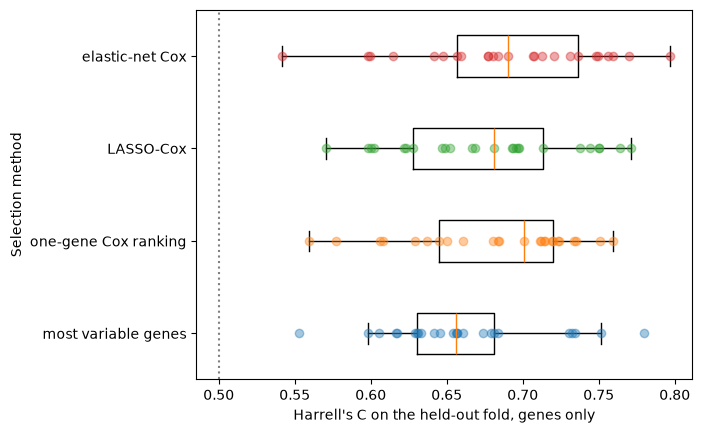

In [21]:
figure, axis = plt.subplots()
axis.boxplot([runs[name]["harrell_genes_only"] for name in selection_methods], orientation="horizontal", showfliers=False)
for position, name in enumerate(selection_methods, start=1):
    axis.plot(runs[name]["harrell_genes_only"], np.full(len(runs[name]), position), "o", alpha=0.4)  # see-through dots show overlapping folds
axis.axvline(0.5, linestyle=":", color="grey")  # chance level
axis.set_yticks(range(1, len(selection_methods) + 1), selection_methods)
axis.set_xlabel("Harrell's C on the held-out fold, genes only")
axis.set_ylabel("Selection method")
plt.show()

Two scores from the same fold share the same patients, so methods are compared by their difference on each fold. The training parts of repeated cross-validation overlap, which makes an ordinary t interval too narrow; the corrected resampled t interval widens it to account for the overlap. The primary comparison, fixed in advance, is whether elastic-net Cox lists score higher than LASSO-Cox lists. The result counts as null if the interval includes 0.

In [22]:
def corrected_interval(differences):
    """Mean difference over repeated cross-validation folds with the corrected resampled t interval."""
    differences = np.asarray(differences, dtype=float)
    count = len(differences)
    spread = np.sqrt((1 / count + 1 / (OUTER_FOLDS - 1)) * differences.var(ddof=1))  # 1 / (folds - 1) = test size over training size
    half = stats.t.ppf((1 + CONFIDENCE) / 2, count - 1) * spread
    return differences.mean(), differences.mean() - half, differences.mean() + half


primary_difference, primary_low, primary_high = corrected_interval(
    runs["elastic-net Cox"]["harrell_genes_only"] - runs["LASSO-Cox"]["harrell_genes_only"])
primary_verdict = "includes 0, so the result is null: the elastic net is not shown to beat LASSO here" \
    if primary_low <= 0 <= primary_high else "excludes 0, so the two methods differ"
primary_sentence = (f"elastic-net Cox minus LASSO-Cox, genes only, is {primary_difference:+.3f} on average, {CONFIDENCE:.0%} interval "
                    f"{primary_low:+.3f} to {primary_high:+.3f}; the interval {primary_verdict}")
display(Markdown(f"Primary comparison: {primary_sentence}."))

Primary comparison: elastic-net Cox minus LASSO-Cox, genes only, is +0.014 on average, 95% interval -0.052 to +0.079; the interval includes 0, so the result is null: the elastic net is not shown to beat LASSO here.

A selection method should also return similar lists when the patients change a little. For each method we compare its lists from all outer folds pair by pair with the Jaccard index, the size of the overlap of two lists divided by the size of their union (1 means identical lists, 0 no shared gene). We also count the stable genes, those present in at least the share of lists named `STABLE_SHARE` in the settings.

In [23]:
def jaccard(first, second):
    union = len(set(first) | set(second))
    return len(set(first) & set(second)) / union if union else 1.0  # two empty lists are identical


def stability(folds):
    lists = list(folds["genes"])
    counts = pd.Series([gene for genes in lists for gene in genes]).value_counts()
    return {"mean pairwise Jaccard": np.mean([jaccard(a, b) for a, b in combinations(lists, 2)]),
            "stable genes": int((counts >= STABLE_SHARE * len(lists)).sum())}


stability_table = pd.DataFrame.from_dict({name: stability(runs[name]) for name in selection_methods}, orient="index")
stability_table.to_csv(RESULTS / "method_comparison_stability.csv")
stability_table.round(3)

,mean pairwise Jaccard,stable genes
most variable genes,0.554,101
one-gene Cox ranking,0.341,144
LASSO-Cox,0.130,7
elastic-net Cox,0.181,23


The table lists the genes that LASSO-Cox and elastic-net Cox select most often, each with the number of outer-fold lists that contain it. Genes are shown by symbol.

In [24]:
def most_selected(folds):
    counts = pd.Series([symbols[gene] for genes in folds["genes"] for gene in genes]).value_counts().head(TOP_GENES)
    return [f"{symbol} ({count})" for symbol, count in counts.items()]


most_selected_genes = pd.DataFrame({name: pd.Series(most_selected(runs[name])) for name in ["LASSO-Cox", "elastic-net Cox"]}).fillna("")
most_selected_genes.index = range(1, len(most_selected_genes) + 1)
most_selected_genes.to_csv(RESULTS / "method_comparison_most_selected_genes.csv")
most_selected_genes

,LASSO-Cox,elastic-net Cox
1,CEL (23),CEL (24)
2,SERPINA1 (22),SERPINA1 (24)
3,ASAH2B (21),ST7-AS1 (24)
4,NLRP2 (20),CXorf56 (23)
5,MAP2K6 (20),NLRP2 (23)
6,HSPA2 (20),MAP2K6 (23)
7,ST7-AS1 (20),GNG4 (23)
8,GNG4 (19),CYTL1 (23)
9,CYTL1 (19),ASAH2B (23)
10,MCTS1 (19),HSPA2 (22)


The choice rule was fixed in advance. Take the method with the highest mean C, genes only. Every method whose corrected interval against it includes 0 is tied with it. Among tied methods prefer one that uses no outcome (only the most variable genes), then the one with the higher Jaccard index. The remaining pairwise differences and everything under genes plus clinical are exploratory. The rule gives a proposal; adopting it is a separate decision.

In [25]:
mean_c = {name: runs[name]["harrell_genes_only"].mean() for name in selection_methods}
best = max(mean_c, key=mean_c.get)
against_best = {name: corrected_interval(runs[best]["harrell_genes_only"] - runs[name]["harrell_genes_only"])
                for name in selection_methods if name != best}
tied = [best] + [name for name, (_, low, high) in against_best.items() if low <= 0 <= high]
chosen = min(tied, key=lambda name: (METHODS[name]["uses outcomes"] != "no", -stability_table.loc[name, "mean pairwise Jaccard"]))
against_best_table = pd.DataFrame(against_best, index=["best minus method", "interval low", "interval high"]).T.round(3)
against_best_table.to_csv(RESULTS / "method_comparison_against_best.csv")
display(against_best_table)
display(Markdown(f"Highest mean C, genes only: {best} ({mean_c[best]:.3f}). Tied with it: {', '.join(tied[1:]) or 'no other method'}. "
                 f"The rule picks {chosen}."))

,best minus method,interval low,interval high
most variable genes,0.029,-0.027,0.086
one-gene Cox ranking,0.009,-0.045,0.063
LASSO-Cox,0.014,-0.052,0.079


Highest mean C, genes only: elastic-net Cox (0.690). Tied with it: most variable genes, one-gene Cox ranking, LASSO-Cox. The rule picks most variable genes.

In the genes plus clinical form each list is combined with the clinical covariates and compared with the clinical-only model on the same folds. These differences are exploratory.

In [26]:
clinical_only = runs["clinical only"]["harrell_genes_plus_clinical"]
against_clinical = pd.DataFrame({name: corrected_interval(runs[name]["harrell_genes_plus_clinical"] - clinical_only) for name in selection_methods},
                                index=["genes plus clinical minus clinical only", "interval low", "interval high"]).T.round(3)
against_clinical.to_csv(RESULTS / "method_comparison_genes_plus_clinical_against_clinical_only.csv")
against_clinical

,genes plus clinical minus clinical only,interval low,interval high
most variable genes,-0.005,-0.032,0.022
one-gene Cox ranking,-0.005,-0.060,0.050
LASSO-Cox,0.001,-0.051,0.053
elastic-net Cox,-0.005,-0.054,0.044


## Leakage check

Selection on all patients means: the selection runs once on all development patients, tuning included, and then only the scoring model is cross-validated on the same outer folds. Selection inside the training fold is the nested result above. For the one-gene Cox ranking both ways use lists of the fixed length `LEAKAGE_LIST_SIZE`. The difference between the two is the score that comes from letting the held-out patients take part in the selection.

In [27]:
ranking = "one-gene Cox ranking"
leakage_methods = {ranking: {"kind": "ranking by score test", "sizes": [LEAKAGE_LIST_SIZE]},
                   "LASSO-Cox": METHODS["LASSO-Cox"], "elastic-net Cox": METHODS["elastic-net Cox"]}
lists_on_all = {name: saved("leakage check", name, "list selected on all patients", compute=lambda method=method: selected_on_all(method, data))
                for name, method in leakage_methods.items()}
on_all = {name: pd.DataFrame(saved("leakage check", name, ON_ALL, compute=lambda genes=genes: run_method(fixed_list(genes), data, OUTER_SEEDS)))
          for name, genes in lists_on_all.items()}
inside = {ranking: pd.DataFrame(saved("leakage check", ranking, INSIDE, compute=lambda: run_method(leakage_methods[ranking], data, OUTER_SEEDS))),
          "LASSO-Cox": runs["LASSO-Cox"], "elastic-net Cox": runs["elastic-net Cox"]}
leakage_rows = {}
for name in leakage_methods:
    difference, low, high = corrected_interval(on_all[name]["harrell_genes_only"] - inside[name]["harrell_genes_only"])
    leakage_rows[name] = {f"C, {ON_ALL}": on_all[name]["harrell_genes_only"].mean(),
                          f"C, {INSIDE}": inside[name]["harrell_genes_only"].mean(),
                          "difference": difference, "interval low": low, "interval high": high,
                          f"genes, {ON_ALL}": len(lists_on_all[name]),
                          f"genes, {INSIDE} (median)": inside[name]["genes"].map(len).median()}
leakage_table = pd.DataFrame.from_dict(leakage_rows, orient="index")
leakage_table.to_csv(RESULTS / "leakage_check_table.csv")
leakage_table.round(3)

,"C, selection on all patients","C, selection inside the training fold",difference,interval low,interval high,"genes, selection on all patients","genes, selection inside the training fold (median)"
one-gene Cox ranking,0.765,0.641,0.124,0.070,0.178,100,100.0
LASSO-Cox,0.963,0.677,0.286,0.218,0.354,172,173.0
elastic-net Cox,0.946,0.690,0.255,0.190,0.321,147,292.0


## The supervisor's questions

Each question raised at the meeting is a heading below. The answers are rendered from the results above.

In [28]:
gain = leakage_table["difference"]
answers = {
    "Why LASSO, why the elastic net or other methods, and which one is better here":
        f"All methods were compared under one protocol (section Method comparison). For the two penalised methods, {primary_sentence}. "
        f"The rule fixed in advance picks {chosen}; adopting it is a decision for the meeting.",
    "Use nested cross-validation":
        f"Every tuned quantity (list size, penalty, L1 share, ridge penalty of the scoring model) is chosen in {INNER_FOLDS} inner folds "
        f"of each training part. Each of the {OUTER_FOLDS * len(OUTER_SEEDS)} outer folds is used once, for scoring only "
        "(section Nested cross-validation).",
    "Use training, validation and test sets, and investigate leakage":
        "Notebook 1 locked a test set that no notebook has opened since; this notebook works inside the development set, "
        "whose inner and outer folds play the roles of training and validation. "
        f"On shuffled outcomes the pipeline scores {shuffled_table.loc[INSIDE, 'mean C']:.3f} with {INSIDE} and "
        f"{shuffled_table.loc[ON_ALL, 'mean C']:.3f} with {ON_ALL} (section Shuffled-outcome check). On real outcomes, {ON_ALL} "
        f"changes the score by {gain['one-gene Cox ranking']:+.3f} for the one-gene Cox ranking, {gain['LASSO-Cox']:+.3f} for LASSO-Cox "
        f"and {gain['elastic-net Cox']:+.3f} for elastic-net Cox (section Leakage check).",
    "Why LASSO was used two times":
        "The earlier pipeline ran a least-squares LASSO on the survival class twice: first on all patients, which fixed a gene "
        "universe (`select_features_lasso` in `src/preprocessing.py` on branch `deprecated`), and again inside each fold, within "
        "that universe (`scripts/03b_sage_clinical_lasso_honest.py`). The first step saw the patients that later served as "
        "validation folds. Here selection happens once, inside the training part of each fold, starting from the full candidate "
        "pool (section Nested cross-validation)."}
display(Markdown("\n\n".join(f"### {question}\n\n{answer}" for question, answer in answers.items())))

### Why LASSO, why the elastic net or other methods, and which one is better here

All methods were compared under one protocol (section Method comparison). For the two penalised methods, elastic-net Cox minus LASSO-Cox, genes only, is +0.014 on average, 95% interval -0.052 to +0.079; the interval includes 0, so the result is null: the elastic net is not shown to beat LASSO here. The rule fixed in advance picks most variable genes; adopting it is a decision for the meeting.

### Use nested cross-validation

Every tuned quantity (list size, penalty, L1 share, ridge penalty of the scoring model) is chosen in 5 inner folds of each training part. Each of the 25 outer folds is used once, for scoring only (section Nested cross-validation).

### Use training, validation and test sets, and investigate leakage

Notebook 1 locked a test set that no notebook has opened since; this notebook works inside the development set, whose inner and outer folds play the roles of training and validation. On shuffled outcomes the pipeline scores 0.497 with selection inside the training fold and 0.677 with selection on all patients (section Shuffled-outcome check). On real outcomes, selection on all patients changes the score by +0.124 for the one-gene Cox ranking, +0.286 for LASSO-Cox and +0.255 for elastic-net Cox (section Leakage check).

### Why LASSO was used two times

The earlier pipeline ran a least-squares LASSO on the survival class twice: first on all patients, which fixed a gene universe (`select_features_lasso` in `src/preprocessing.py` on branch `deprecated`), and again inside each fold, within that universe (`scripts/03b_sage_clinical_lasso_honest.py`). The first step saw the patients that later served as validation folds. Here selection happens once, inside the training part of each fold, starting from the full candidate pool (section Nested cross-validation).

## Run record

The last block records the git commit of this execution, the package versions, the seeds, the checksum of the input file, and for each saved run the commit that computed it and its running time.

In [29]:
def git(*arguments):
    return subprocess.run(["git", *arguments], capture_output=True, text=True, check=True).stdout.strip()


saved_runs = {path.stem: {key: json.loads(path.read_text())[key] for key in ["git commit", "seconds"]}
              for path in sorted(RESULTS.glob("*.json")) if path.name != "run_record.json"}
run_record = {
    "git commit": git("rev-parse", "HEAD"),
    "tracked files changed since that commit": git("status", "--porcelain", "--untracked-files=no").splitlines(),
    "python": sys.version.split()[0],
    "packages": {name: version(name) for name in ["numpy", "scipy", "pandas", "pyarrow", "scikit-learn", "scikit-survival",
                                                  "joblib", "matplotlib"]},
    "seeds": {"outer folds": OUTER_SEEDS, "inner folds": INNER_SEED, "shuffles": SHUFFLE_SEEDS, "checks": CHECK_SEED},
    "input file (sha256)": {"tcga_development.parquet": file_sha256},
    "saved runs": saved_runs}
(RESULTS / "run_record.json").write_text(json.dumps(run_record, indent=1))
for key, value in run_record.items():
    if key != "saved runs":
        print(f"{key}: {json.dumps(value)}")
pd.DataFrame.from_dict(saved_runs, orient="index")

git commit: "dd2817c2a86d635a12de8bf969b4c6dd85582039"
tracked files changed since that commit: []
python: "3.12.14"
packages: {"numpy": "2.5.3", "scipy": "1.18.1", "pandas": "3.0.6", "pyarrow": "25.0.1", "scikit-learn": "1.9.1", "scikit-survival": "0.28.0", "joblib": "1.6.0", "matplotlib": "3.11.2"}
seeds: {"outer folds": [1, 2, 3, 4, 5], "inner folds": 0, "shuffles": [1, 2, 3, 4, 5], "checks": 0}
input file (sha256): {"tcga_development.parquet": "0dd236e52bcbdc4c0a1a17a552158483da3eb3038e054768276e0e4f87d01127"}


,git commit,seconds
leakage_check_elastic_net_cox_list_selected_on_all_patients,fe72de3902b6122d87542d4d907a0aa35c835f21,105
leakage_check_elastic_net_cox_selection_on_all_patients,fe72de3902b6122d87542d4d907a0aa35c835f21,36
leakage_check_lasso_cox_list_selected_on_all_patients,fe72de3902b6122d87542d4d907a0aa35c835f21,43
leakage_check_lasso_cox_selection_on_all_patients,fe72de3902b6122d87542d4d907a0aa35c835f21,38
leakage_check_one_gene_cox_ranking_list_selected_on_all_patients,fe72de3902b6122d87542d4d907a0aa35c835f21,3
leakage_check_one_gene_cox_ranking_selection_inside_the_training_fold,fe72de3902b6122d87542d4d907a0aa35c835f21,50
leakage_check_one_gene_cox_ranking_selection_on_all_patients,fe72de3902b6122d87542d4d907a0aa35c835f21,34
method_comparison_clinical_only,fe72de3902b6122d87542d4d907a0aa35c835f21,6
method_comparison_elastic_net_cox,fe72de3902b6122d87542d4d907a0aa35c835f21,1192
method_comparison_lasso_cox,fe72de3902b6122d87542d4d907a0aa35c835f21,585
